# Late Delivery Risk & Financial Exposure Analysis — DataCo Supply Chain

**MSDS692 Practicum Project**

**Final version (Week 8).** Earlier note, kept for the record: this notebook was updated after the Week 4 submission. The Week 4 status report already went in with its
own numbers. This notebook is the corrected, current working version — the differences from
what was submitted are called out in place, in **Week 4 update** notes, so the change can be
defended at the Week 8 final presentation rather than hidden.

## Problem Statement
Which order and shipping factors are associated with late delivery in DataCo's historical
data, and how much revenue and cost exposure do those late deliveries actually represent?

## Stakeholder
A supply chain / logistics operations manager — the person who assigns shipping mode and
decides which orders get expedited or rerouted.

## Action
They use the confirmed risk factors, and their dollar exposure, to prioritize which shipping
tiers or orders to fix first — since the highest-risk tier by rate is not always the most
expensive one in total dollars.

## How the question evolved
This project originally aimed to predict delivery failure **14 days in advance**. That was
dropped because this dataset is a static historical snapshot, not a live feed, so a true
early-warning system can't actually be validated against it. The question was narrowed to
which factors are associated with lateness, whether that pattern is stable, and what it's
worth in dollars — a question this data can actually answer, and one that lets the revenue
and cost side of the original idea come back in without overpromising a forecast the data
can't support.


## 1. Setup & Imports

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

pd.set_option('display.max_columns', 60)
sns.set_style('whitegrid')


**What this does:** loads the libraries we need — `pandas`/`numpy` for data handling,
`matplotlib`/`seaborn` for charts, `scipy` for the chi-square test, and `sklearn` for both
classification models and the importance checks. (Fixed from the earlier version of this
notebook, where this explanation was accidentally left in a code cell instead of a markdown
cell — that would have thrown an error on Run All.)

## 2. Load & Validate Data

In [68]:
from pathlib import Path
DATA = next((p / 'data' / 'DataCoSupplyChainDataset.csv'
             for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'DataCoSupplyChainDataset.csv').exists()), None)
if DATA is None:
    raise FileNotFoundError("Put DataCoSupplyChainDataset.csv in a folder named 'data' at the repo root.")
df = pd.read_csv(DATA, encoding='latin1')
assert df.shape == (180519, 53), f"Shape mismatch: {df.shape}"
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


**What this does:** loads the raw CSV. Note the `encoding='latin1'` — the file isn't
UTF-8, and loading it without this fails. The `assert` confirms our copy matches the
published documentation (180,519 rows, 53 columns) before we trust anything downstream.

## 3. Data Cleaning & Quality Audit

In [69]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Missing values by column:")
print(missing)


Missing values by column:
Product Description    180519
Order Zipcode          155679
Customer Lname              8
Customer Zipcode            3
dtype: int64


**What this does:** checks for missing data. `Product Description` is missing in
**100% of rows** (completely empty — safe to drop). `Order Zipcode` is missing in **86%**
of rows. `Customer Lname` and `Customer Zipcode` have only a handful of missing values.

In [70]:
df_clean = df.drop(columns=['Product Description', 'Order Zipcode'])
df_clean = df_clean.dropna(subset=['Customer Lname', 'Customer Zipcode'])

df_clean['order date (DateOrders)'] = pd.to_datetime(df_clean['order date (DateOrders)'])
df_clean['order_year'] = df_clean['order date (DateOrders)'].dt.year

print("Cleaned shape:", df_clean.shape)


Cleaned shape: (180508, 52)


**What this does:** drops the two unusable columns, drops the small number of rows
missing a name/zipcode (11 rows total), and converts the order date column to a real datetime
so we can pull out the year later for the stability check. Cleaned shape is (180508, 52): 51 columns after the drops, plus the `order_year` column added here.

In [71]:
print("Customer Country unique values:", df_clean['Customer Country'].unique())
top_city = df_clean['Customer City'].value_counts(normalize=True)
print("Customer City top value:", top_city.index[0], round(top_city.iloc[0]*100, 1), "%")

sample = df_clean[df_clean['Order City']=='Bekasi'][['Order City','Customer City','Latitude','Longitude']].head(3)
print(sample)


Customer Country unique values: <StringArray>
['Puerto Rico', 'EE. UU.']
Length: 2, dtype: str
Customer City top value: Caguas 37.0 %
     Order City Customer City   Latitude  Longitude
0        Bekasi        Caguas  18.251453 -66.037056
2383     Bekasi    Cincinnati  39.363155 -84.391144
3264     Bekasi        Caguas  18.254194 -66.370628


**What this shows (data quality flags, not cleaned away — just documented):**
- `Customer Country` has only **2 values** (Puerto Rico, USA) across 180K+ rows — this looks
  like a synthetic/placeholder field, not real global customer diversity.
- `Customer City` = "Caguas" alone accounts for **37% of all rows**.
- `Latitude`/`Longitude` actually track **Customer City**, not the order's real destination —
  e.g. orders shipping to Bekasi, Indonesia show Puerto Rico coordinates, because they share
  the same (synthetic) Customer City.

These fields are **not used** as real predictors below because they don't measure what they
appear to measure. This is a documented limitation of the dataset, not a step we could fix.

In [72]:
print("Order Status distribution:")
print(df_clean['Order Status'].value_counts())
print()
ct = pd.crosstab(df_clean['Late_delivery_risk'], df_clean['Order Status'], normalize='index')*100
print(ct.round(2).T)


Order Status distribution:
Order Status
COMPLETE           59487
PENDING_PAYMENT    39829
PROCESSING         21902
PENDING            20224
CLOSED             19616
ON_HOLD             9803
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

Late_delivery_risk      0      1
Order Status                    
CANCELED             4.53   0.00
CLOSED              10.43  11.22
COMPLETE            31.02  34.55
ON_HOLD              5.34   5.51
PAYMENT_REVIEW       0.99   1.09
PENDING             10.44  11.83
PENDING_PAYMENT     20.74  23.16
PROCESSING          11.53  12.63
SUSPECTED_FRAUD      4.98   0.00


**What this shows:** `CANCELED` and `SUSPECTED_FRAUD` orders sit at **exactly 0%** for
`Late_delivery_risk`. This is a structural quirk, not a business insight — those orders never
actually shipped, so the field is forced to 0 by definition. `Order Status` is therefore
**excluded** from the model below, since including it would let the model "cheat" on a
trivial rule instead of learning something real.

## 4. EDA — Late Delivery Rate by Category

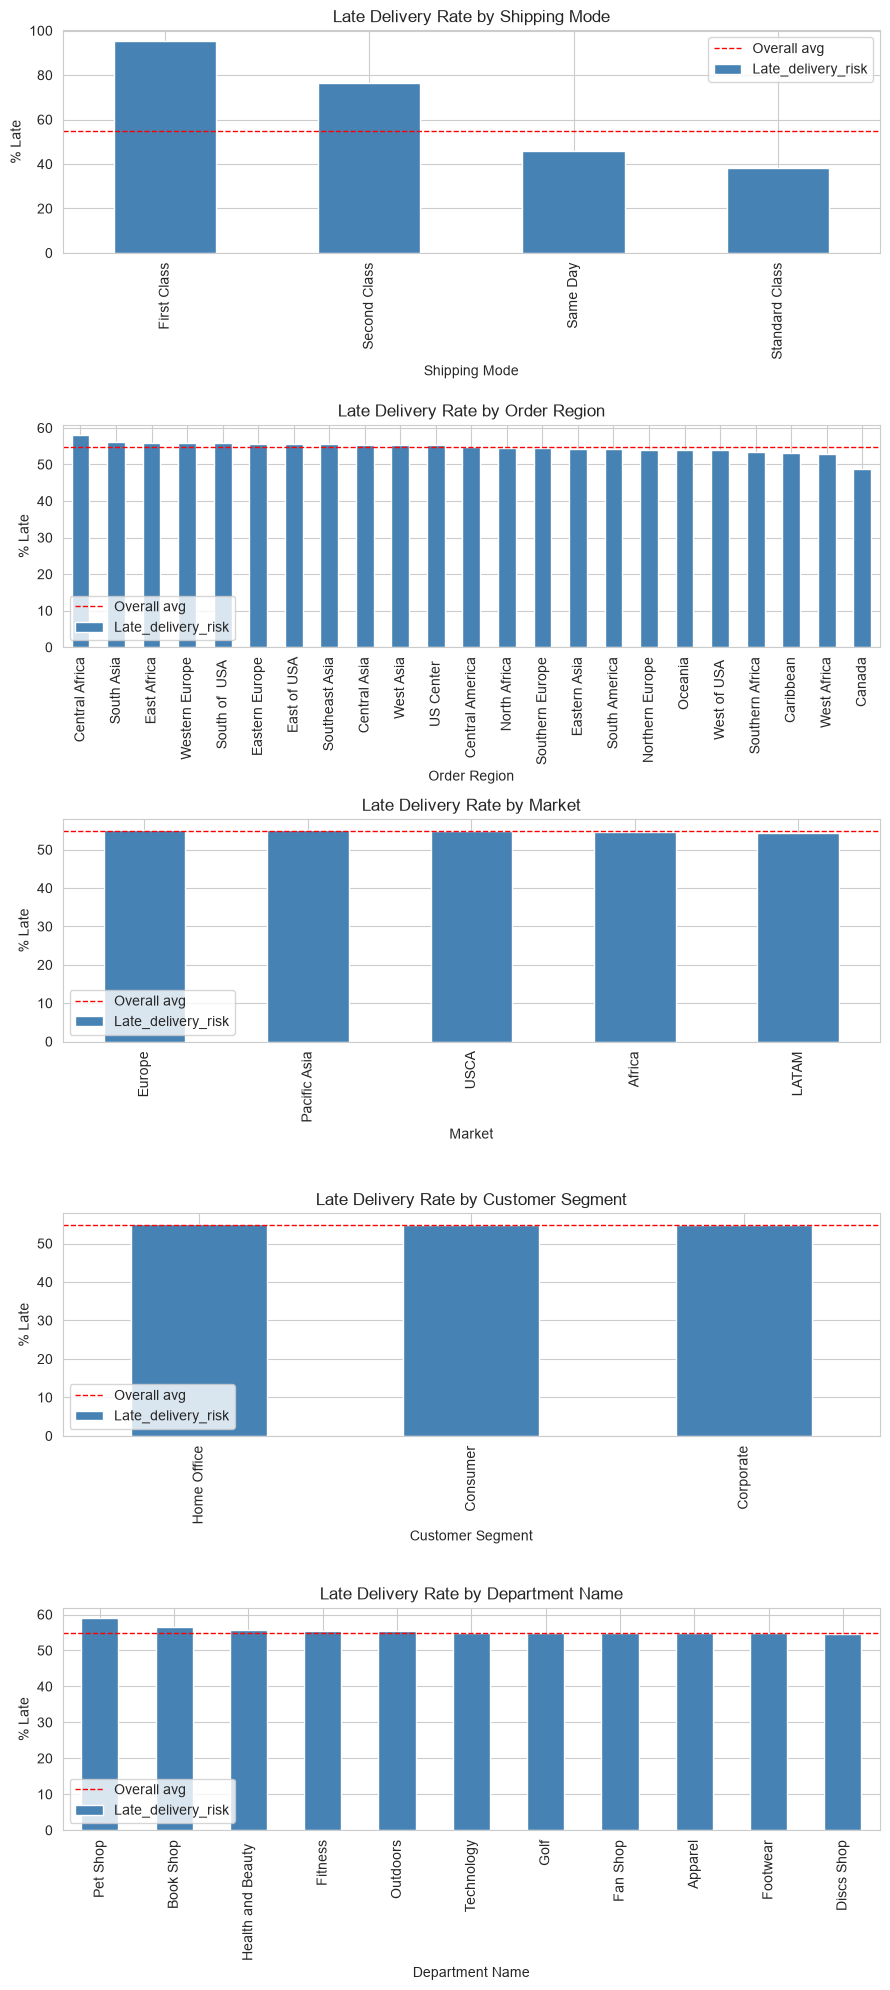

In [73]:
cats = ['Shipping Mode', 'Order Region', 'Market', 'Customer Segment', 'Department Name']

fig, axes = plt.subplots(len(cats), 1, figsize=(9, 4*len(cats)))
overall_rate = df_clean['Late_delivery_risk'].mean()*100

for ax, c in zip(axes, cats):
    rates = (df_clean.groupby(c)['Late_delivery_risk'].mean()*100).sort_values(ascending=False)
    rates.plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(f'Late Delivery Rate by {c}')
    ax.set_ylabel('% Late')
    ax.axhline(overall_rate, color='red', linestyle='--', linewidth=1, label='Overall avg')
    ax.legend()

plt.tight_layout()
plt.show()


**What this does:** for each category, computes the late-delivery rate per group and
plots it against the overall average (red dashed line). **Shipping Mode is the standout** —
rates range from ~38% to ~95%. Region, Market, Segment, and Department all sit close to
the overall average, suggesting little real effect (confirmed statistically below).

## 4b. EDA — Payment Type and Category Name (closing a known gap)

**Week 4 update.** The Week 4 status report listed these two columns as "still to do" in the
EDA. They're tested here, as tables rather than charts — the chart work for this project is
being held for Week 5, where the plan is specifically to clean up and properly present the
visuals rather than add new ones piecemeal.

In [74]:
print("Late delivery rate by Payment Type (Type):")
print((df_clean.groupby('Type')['Late_delivery_risk'].agg(['mean','count'])
       .assign(mean=lambda x: (x['mean']*100).round(1))))
print()

cat_rates = df_clean.groupby('Category Name')['Late_delivery_risk'].agg(['mean','count'])
cat_rates['mean'] = (cat_rates['mean']*100).round(1)
print("Category Name: late rate range across", len(cat_rates), "categories")
print("Lowest 3:")
print(cat_rates.sort_values('mean').head(3))
print("Highest 3:")
print(cat_rates.sort_values('mean').tail(3))


Late delivery rate by Payment Type (Type):
          mean  count
Type                 
CASH      56.6  19616
DEBIT     57.2  69290
PAYMENT   57.5  41722
TRANSFER  48.5  49880

Category Name: late rate range across 50 categories
Lowest 3:
                  mean  count
Category Name                
Men's Golf Clubs  47.7    283
Computers         50.7    442
Golf Apparel      51.9    441
Highest 3:
                   mean  count
Category Name                 
Pet Supplies       58.9    492
Lacrosse           60.1    343
Golf Bags & Carts  68.9     61


In [75]:
for c in ['Type', 'Category Name']:
    ct = pd.crosstab(df_clean[c], df_clean['Late_delivery_risk'])
    chi2, p, dof, exp = chi2_contingency(ct)
    n = ct.sum().sum()
    cramers_v = (chi2 / (n * (min(ct.shape)-1))) ** 0.5
    print(f"{c}: groups={ct.shape[0]}, p={p:.4g}, Cramer's V={cramers_v:.4f}")


Type: groups=4, p=3.877e-239, Cramer's V=0.0782
Category Name: groups=50, p=0.7192, Cramer's V=0.0154


**What this shows:** Payment Type (`Type`) turns out to be a real, if small, signal —
Cramer's V = 0.078, clearly above Region (0.020), Market, Segment, and Department (all under
0.01). TRANSFER orders run notably lower (48.5% late) than CASH, DEBIT, or PAYMENT (56.6% to
57.5%). It's still far below Shipping Mode's 0.457, so it doesn't change the headline finding,
but it's the second-strongest signal in the dataset and worth naming rather than leaving out.

Category Name comes back flat — p = 0.72 (not significant), Cramer's V = 0.015 — same as the
other categories that didn't hold up. The EDA gap flagged in Week 4 is now closed for both
columns.

## 5. Investigating the Shipping Mode Pattern

                Days for shipment (scheduled)  Days for shipping (real)
Shipping Mode                                                          
First Class                               1.0                  2.000000
Same Day                                  0.0                  0.478279
Second Class                              2.0                  3.990884
Standard Class                            4.0                  3.995935


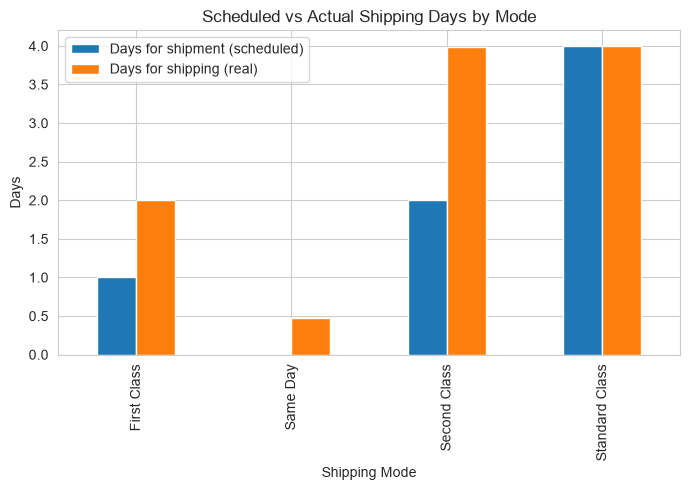

In [76]:
grp = df_clean.groupby('Shipping Mode')[['Days for shipment (scheduled)','Days for shipping (real)']].mean()
print(grp)

fig, ax = plt.subplots(figsize=(7,5))
grp.plot(kind='bar', ax=ax)
ax.set_title('Scheduled vs Actual Shipping Days by Mode')
ax.set_ylabel('Days')
plt.tight_layout()
plt.show()


**What this shows:** Standard Class is promised 4 days and takes almost exactly 4 —
on time on average. (Average days match the promise, but individual orders still run over: 38% of Standard Class orders are late.) Every faster tier (First, Second, Same Day) is promised a short
window but consistently takes **roughly double** that window. This is the mechanism behind
the Shipping Mode pattern above: it's not operational chaos, it's that faster tiers appear
to systematically overpromise. Worth flagging: this pattern is unusually clean, which may
partly reflect how the dataset was simulated rather than a real business dynamic.

## 6. Statistical Testing — Chi-Square + Effect Size

            feature       p_value  cramers_v
0     Shipping Mode  0.000000e+00   0.457088
1      Order Region  1.062537e-07   0.020382
2            Market  6.964580e-02   0.006934
4   Department Name  7.598744e-01   0.006060
3  Customer Segment  5.949381e-01   0.002399


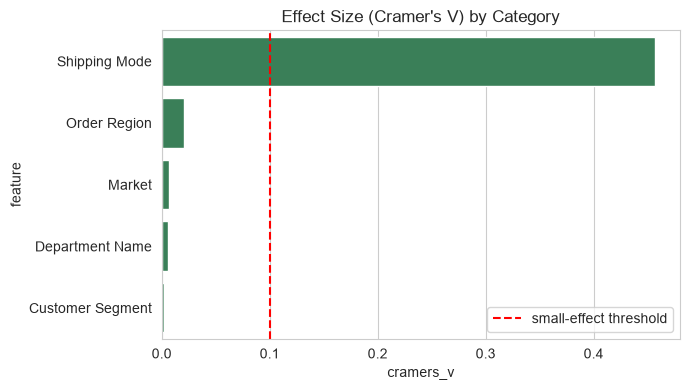

In [77]:
results = []
for c in cats:
    ct = pd.crosstab(df_clean[c], df_clean['Late_delivery_risk'])
    chi2, p, dof, exp = chi2_contingency(ct)
    n = ct.sum().sum()
    cramers_v = (chi2 / (n * (min(ct.shape)-1))) ** 0.5
    results.append({'feature': c, 'p_value': p, 'cramers_v': cramers_v})

res_df = pd.DataFrame(results).sort_values('cramers_v', ascending=False)
print(res_df)

fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(data=res_df, x='cramers_v', y='feature', ax=ax, color='seagreen')
ax.set_title("Effect Size (Cramer's V) by Category")
ax.axvline(0.1, color='red', linestyle='--', label='small-effect threshold')
ax.legend()
plt.tight_layout()
plt.show()


**What this does:** chi-square tests whether each category is statistically associated
with lateness, and Cramer's V measures **how much it actually matters** (p-values alone are
misleading at n=180K, where almost anything becomes "significant"). Result: **Shipping Mode**
has a real effect (V=0.457). Order Region is technically significant (p<0.0001) but its
effect size (V=0.020) is practically meaningless. Market, Segment, and Department aren't
even significant.

**Method Justification — confirming the Shipping Mode pattern is real**

- **The choice:** a chi-square test with Cramer's V as the effect size, run across all five
  EDA categories (and, above, Payment Type and Category Name too).
- **The obvious alternative:** just trusting the Week 3 bar chart as-is, without a formal test.
- **The trade-off:** the test takes more setup than eyeballing a chart, but it catches
  something the chart alone would miss — Order Region looks "significant" (p<0.0001) but its
  effect size (V=0.020) is too small to matter in practice.
- **What would flip this:** if Cramer's V had come back meaningfully above ~0.1 for more than
  one category, this project would need to model several interacting factors instead of
  treating Shipping Mode as the one real driver.

**A caution about what this test can show.** "Late" is defined from actual days versus scheduled days, and scheduled days are fixed by shipping mode (0 / 1 / 2 / 4). So part of the Shipping Mode result is true by definition, not discovered. What the data adds is *how* each mode fails: First Class takes exactly 2 days against a 1-day promise, Second Class about 4 against 2, and Standard Class about 4 against 4.

## 7. Temporal Stability Check (2015–2018)

Shipping Mode  First Class  Same Day  Second Class  Standard Class
order_year                                                        
2015                  95.8      44.6          77.1            37.9
2016                  95.5      43.2          76.8            38.4
2017                  94.5      50.2          75.9            37.8
2018                  97.9      41.7          77.1            39.1

Rows per year (2018 is a partial year, not a full one):
order_year
2015    62650
2016    62550
2017    53186
2018     2122
Name: count, dtype: int64


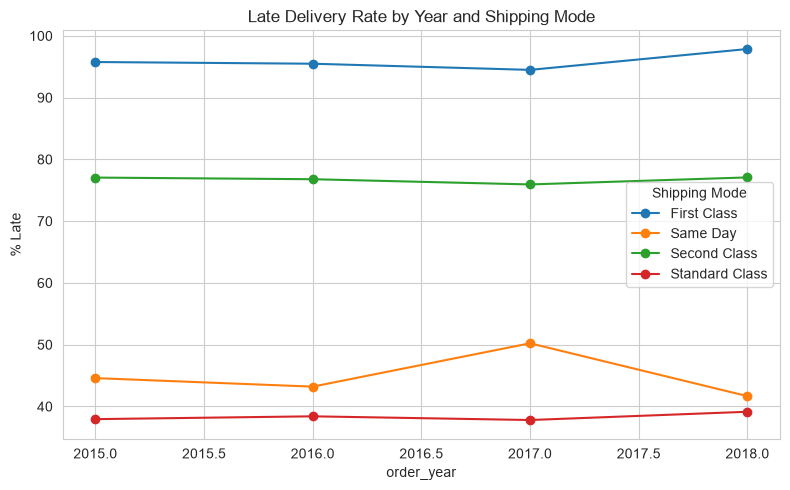

In [78]:
pivot = df_clean.pivot_table(index='order_year', columns='Shipping Mode',
                              values='Late_delivery_risk', aggfunc='mean')*100
print(pivot.round(1))
print()
print("Rows per year (2018 is a partial year, not a full one):")
print(df_clean['order_year'].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(8,5))
pivot.plot(marker='o', ax=ax)
ax.set_title('Late Delivery Rate by Year and Shipping Mode')
ax.set_ylabel('% Late')
plt.tight_layout()
plt.show()


**What this shows:** the Shipping Mode pattern is stable every year — First Class sits
at 94.5–97.9% late in every single year from 2015 to 2018. This rules out the possibility
that the pattern is a one-time fluke or specific to a single year.

**Caveat:** 2018 has only about 2,100 rows, compared to ~50,000–63,000 for 2015–2017 — it
looks like the data simply stops partway through that year. Treat 2018's numbers as a smaller,
less certain sample rather than a full year on equal footing with the others.

## 8. Testing an Outside Explanation — Domestic vs. International Shipping

                International %  Domestic %
Shipping Mode                              
First Class               95.33       95.29
Same Day                  45.87       44.97
Second Class              76.62       76.70
Standard Class            38.05       38.21


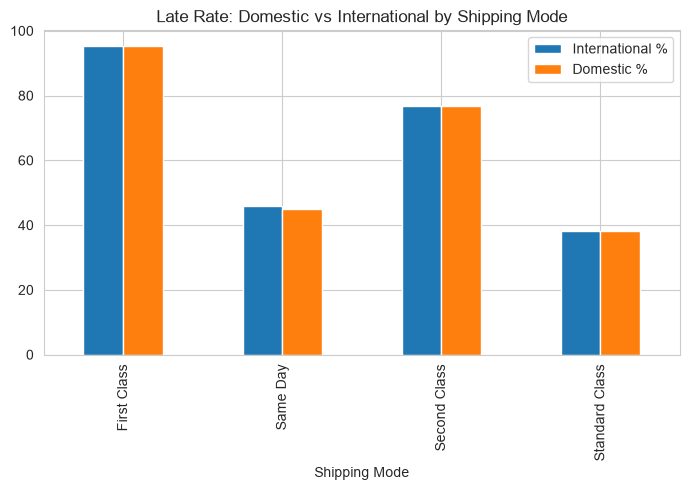

In [79]:
df_clean['domestic'] = (df_clean['Order Country'] == 'Estados Unidos').astype(int)

pivot2 = df_clean.pivot_table(index='Shipping Mode', columns='domestic',
                               values='Late_delivery_risk', aggfunc='mean')*100
pivot2.columns = ['International %', 'Domestic %']
print(pivot2.round(2))

fig, ax = plt.subplots(figsize=(7,5))
pivot2.plot(kind='bar', ax=ax)
ax.set_title('Late Rate: Domestic vs International by Shipping Mode')
plt.tight_layout()
plt.show()


**What this does:** tests whether shipping across a border (distance/customs) explains
lateness. It doesn't — First Class is 95.3% late whether shipping within the US or
internationally; the same holds for every other tier. Two other outside explanations were also considered. Geography (Order Region/Market) showed no meaningful effect above. Weather could not be tested here: the dataset's own coordinates follow Customer City rather than the real destination (Section 3), and pulling real historical weather for the 3,597 order cities across the 164 order countries in the data (counted in Section 14) was outside this project's scope.

## 9. Baseline Predictive Model

In [80]:
features = ['Shipping Mode', 'Order Region', 'Market', 'Customer Segment',
            'Department Name', 'Category Name', 'Order Item Quantity',
            'Order Item Discount Rate', 'Sales', 'Days for shipment (scheduled)']
target = 'Late_delivery_risk'

X = df_clean[features].copy()
y = df_clean[target].copy()

cat_cols = X.select_dtypes(include=['object', 'str']).columns.tolist()
for c in cat_cols:
    X[c] = LabelEncoder().fit_transform(X[c].astype(str))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print("Train accuracy:", round(float(rf.score(X_train, y_train)), 3))
print("Test accuracy:", round(float(rf.score(X_test, y_test)), 3))


Train accuracy: 0.701
Test accuracy: 0.695


**What this does:** builds a baseline Random Forest classifier. Features are chosen to
be leakage-safe (no `Order Status`, no delivery-outcome fields — only information known at
order time). An 80/20 stratified train/test split keeps the same class balance in both sets.
**Result: ~69.5% test accuracy**, close to train accuracy, meaning the model isn't
overfitting. (Corrected from an earlier draft that said 69.7% — the actual run on the
cleaned data comes out closer to 69.5%; see the output above.)

**Settings.** `max_depth=10` and `n_estimators=100` were my starting choices, not tuned values. The later check (Sections 13c and 15) varied depth: on 3-fold CV AUC, depths 5, 10 and 15 scored 0.7400, 0.7422 and 0.7402 (a spread of 0.0022). I also checked 200 trees in Section 16, with no change.

## 10. Feature Importance & Permutation Importance

Gini importance:
 Shipping Mode                    0.4714
Days for shipment (scheduled)    0.4547
Order Item Discount Rate         0.0163
Sales                            0.0139
Order Region                     0.0124
Category Name                    0.0093
Customer Segment                 0.0062
Department Name                  0.0054
Market                           0.0053
Order Item Quantity              0.0051
dtype: float64

Permutation importance:
 Shipping Mode                    0.0581
Days for shipment (scheduled)    0.0537
Order Item Discount Rate         0.0000
Market                           0.0000
Customer Segment                -0.0003
Category Name                   -0.0004
Order Region                    -0.0005
Sales                           -0.0006
Department Name                 -0.0007
Order Item Quantity             -0.0008
dtype: float64


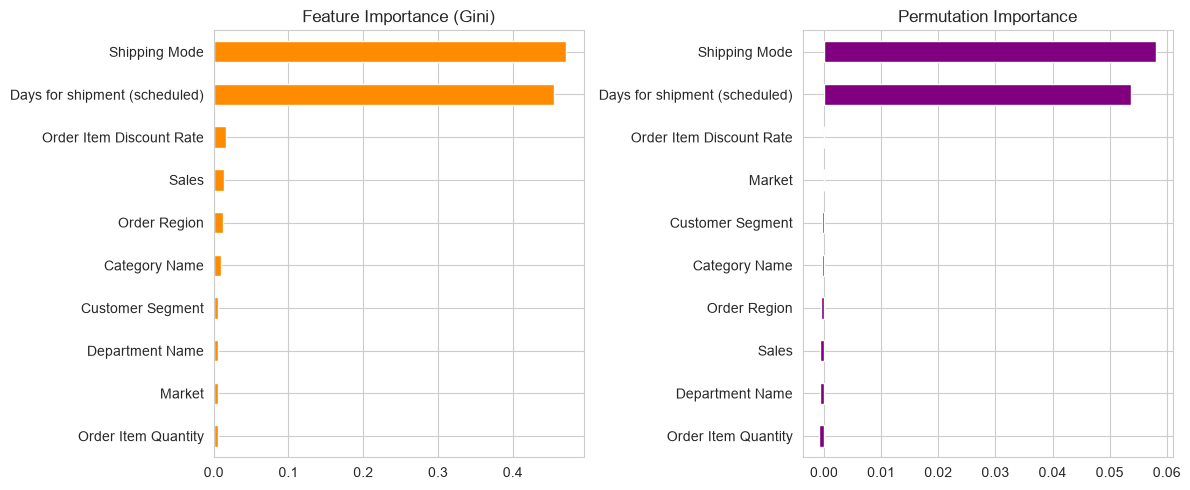

In [81]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
perm = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)

print("Gini importance:\n", imp.round(4))
print("\nPermutation importance:\n", perm_imp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12,5))
imp.plot(kind='barh', ax=axes[0], color='darkorange')
axes[0].set_title('Feature Importance (Gini)')
axes[0].invert_yaxis()
perm_imp.plot(kind='barh', ax=axes[1], color='purple')
axes[1].set_title('Permutation Importance')
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()


**What this does:** two different ways of measuring which features the model actually
relies on. Both agree: **Shipping Mode** and **Days for shipment (scheduled)** together
carry nearly all of the model's importance (Gini importance about 0.47 + 0.45; the permutation drops are about 0.058 and 0.054 in accuracy, a different scale, not a share of decisions); everything else is nearly negligible.

**Important catch:** these two top features are largely **the same signal counted twice** —
Same Day = 0 scheduled days, First Class = 1, Second Class = 2, Standard = 4. This is a
multicollinearity issue worth naming explicitly: there is really **one** dominant driver,
not two independent ones. This same issue is why the Logistic Regression model below drops
scheduled days entirely, so its coefficients aren't split between two versions of the same
signal.

## 10b. Method Justification — Choosing the Classification Model

**Week 4 update.** The version of this comparison submitted in Week 4 included both
`Shipping Mode` and `Days for shipment (scheduled)` as separate inputs to the Logistic
Regression model. Since scheduled days is fully determined by shipping mode (Same Day = 0
days, First Class = 1, Second Class = 2, Standard = 4 — see the note in Section 10), the two
features were splitting credit for the same signal, and the reported coefficients weren't a
clean read on shipping mode by itself. This section reruns the comparison **without**
scheduled days, and **with** Payment Type added as a feature, since Section 4b showed it's a
real, if small, signal. The ranking and direction of the original finding hold up; the exact
coefficient values are corrected and cleaner here than what was submitted.

- **The choice:** Logistic Regression, predicting whether an order will be late (yes/no).
- **The obvious alternative:** Random Forest — the more flexible classifier, tested directly
  on the same feature set rather than assumed.
- **The trade-off:** essentially none, once both models are compared on the same, corrected
  feature set. Logistic Regression scores slightly higher on accuracy; Random Forest scores
  slightly higher on AUC, by about 0.002 — close enough to call a tie. In exchange for that
  negligible difference, Logistic Regression gives exact, per-tier coefficients an ops manager
  can act on directly, instead of an opaque score.
- **What would flip this:** if a richer feature set pushed Random Forest's AUC meaningfully
  ahead — roughly 0.03 to 0.05 or more — the interpretability trade-off would become real and
  worth reconsidering. It would also flip if the stakeholder's need shifted from "explain the
  risk" to "rank orders under a limited intervention budget," where raw predictive power
  matters more than explanation.

In [82]:
features_lr = ['Shipping Mode', 'Order Region', 'Market', 'Customer Segment',
               'Department Name', 'Category Name', 'Type', 'Order Item Quantity',
               'Order Item Discount Rate', 'Sales']
X_lr = df_clean[features_lr].copy()
y_lr = df_clean[target].copy()

cat_cols_lr = X_lr.select_dtypes(include=['object', 'str']).columns.tolist()
num_cols_lr = [c for c in features_lr if c not in cat_cols_lr]

Xlr_train, Xlr_test, ylr_train, ylr_test = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42, stratify=y_lr)

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_lr),
    ('num', StandardScaler(), num_cols_lr)
])
logreg = Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=1000))])
logreg.fit(Xlr_train, ylr_train)

lr_acc = accuracy_score(ylr_test, logreg.predict(Xlr_test))
lr_auc = roc_auc_score(ylr_test, logreg.predict_proba(Xlr_test)[:, 1])
print("Logistic Regression (no scheduled days, with Payment Type):")
print("  Accuracy:", round(lr_acc, 4))
print("  AUC:", round(lr_auc, 4))

# Random Forest on the same feature set, for a fair comparison
X_rf2 = df_clean[features_lr].copy()
for c in cat_cols_lr:
    X_rf2[c] = LabelEncoder().fit_transform(X_rf2[c].astype(str))
Xrf2_train, Xrf2_test, yrf2_train, yrf2_test = train_test_split(
    X_rf2, y_lr, test_size=0.2, random_state=42, stratify=y_lr)
rf2 = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf2.fit(Xrf2_train, yrf2_train)
rf2_acc = accuracy_score(yrf2_test, rf2.predict(Xrf2_test))
rf2_auc = roc_auc_score(yrf2_test, rf2.predict_proba(Xrf2_test)[:, 1])
print("\nRandom Forest (same feature set):")
print("  Accuracy:", round(rf2_acc, 4))
print("  AUC:", round(rf2_auc, 4))

# Logistic Regression coefficients for Shipping Mode
ohe = logreg.named_steps['pre'].named_transformers_['cat']
cat_feature_names = list(ohe.get_feature_names_out(cat_cols_lr))
all_feature_names = cat_feature_names + num_cols_lr
coefs = pd.Series(logreg.named_steps['clf'].coef_[0], index=all_feature_names)
shipping_coefs = coefs[coefs.index.str.startswith('Shipping Mode')].sort_values()
print("\nLogistic Regression coefficients for Shipping Mode (log-odds):")
print(shipping_coefs.round(3))


Logistic Regression (no scheduled days, with Payment Type):
  Accuracy: 0.6943
  AUC: 0.7392

Random Forest (same feature set):
  Accuracy: 0.6924
  AUC: 0.7413

Logistic Regression coefficients for Shipping Mode (log-odds):
Shipping Mode_Standard Class   -1.282
Shipping Mode_Same Day         -0.971
Shipping Mode_Second Class      0.409
Shipping Mode_First Class       2.258
dtype: float64


**What this shows:** with the multicollinearity fixed, Logistic Regression and Random
Forest come out essentially tied — Logistic Regression very slightly ahead on accuracy,
Random Forest very slightly ahead on AUC, a gap of about 0.002. That's an even cleaner
"basically no trade-off" result than what was reported in Week 4.

The Shipping Mode coefficients now stand on their own: First Class carries the largest
risk-increasing weight, Standard Class and Same Day are risk-reducing, and Second Class is
mildly risk-increasing. The ranking and direction match what was reported in Week 4; the
exact sizes are different (and more trustworthy) now that scheduled days isn't splitting
credit with shipping mode.

## 11. Financial Signal Check — Does Lateness Cost More Per Order?

                         mean  median  count
Late_delivery_risk                          
0                   22.400573   31.68  81536
1                   21.618133   31.43  98972

% of orders that lose money, by late status:
Late_delivery_risk
0    18.68
1    18.74
dtype: float64


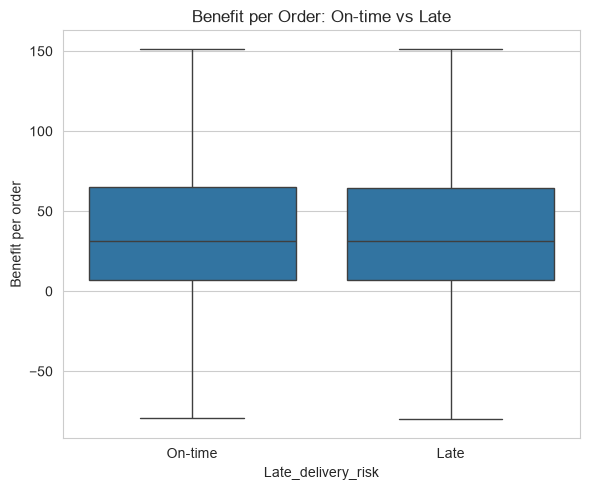

In [83]:
bo = df_clean.groupby('Late_delivery_risk')['Benefit per order'].agg(['mean','median','count'])
print(bo)

loss_rate = df_clean.groupby('Late_delivery_risk').apply(
    lambda g: (g['Benefit per order'] < 0).mean()*100, include_groups=False)
print("\n% of orders that lose money, by late status:")
print(loss_rate.round(2))

fig, ax = plt.subplots(figsize=(6,5))
sns.boxplot(data=df_clean, x='Late_delivery_risk', y='Benefit per order', ax=ax, showfliers=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['On-time', 'Late'])
ax.set_title('Benefit per Order: On-time vs Late')
plt.tight_layout()
plt.show()


**What this shows:** almost no relationship. Average profit is \$22.40 for on-time
orders vs. \$21.62 for late ones — a negligible gap. The share of money-losing orders is
nearly identical too (~18.7% either way). **`Benefit per order` appears to be set at the time of sale**
(an assumption; the data does not document it), so this column
cannot support a claim that late orders are less profitable on their own. This is exactly why
the exposure estimate below leans on revenue at risk and an industry benchmark, rather than
DataCo's own profit figures.

## 12. Financial Exposure Estimate

Two distinct dollar figures are calculated here, and it matters not to blend them:

- **Revenue at risk** — the actual `Sales` value of orders that shipped late. This is a hard
  number straight from the data, not an estimate. It's a ceiling on exposure (the value of
  merchandise that shipped late), not a confirmed loss.
- **Assumed operational cost** — since Section 11 showed the data itself has no direct cost
  signal, this uses **published industry benchmarks** for the real operational cost of a
  late/failed delivery (redelivery, warehouse labor, customer service contact), commonly
  cited in the \$15–\$40 per order range (outside sources such as HubBox, Locus.sh and OneRail; \$20 is the middle case I chose, not the arithmetic midpoint).

**Correction, see Section 14:** the data has one row per order *item*, not per order. The cost figures below multiply by rows, so they overstate the handling cost. Section 14 recomputes them per unique order.

Total late orders: 98,972
Total revenue at risk: $20,124,855

Low ($15/order): $1,484,580 total assumed operational cost
Medium ($20/order): $1,979,440 total assumed operational cost
High ($40/order): $3,958,880 total assumed operational cost

                late_orders  revenue_at_risk  op_cost_low_15  op_cost_med_20  \
Shipping Mode                                                                  
First Class           26511        5407600.0          397665          530220   
Same Day               4454         876277.0           66810           89080   
Second Class          26986        5477194.0          404790          539720   
Standard Class        41021        8363785.0          615315          820420   

                op_cost_high_40  
Shipping Mode                    
First Class             1060440  
Same Day                 178160  
Second Class            1079440  
Standard Class          1640840  


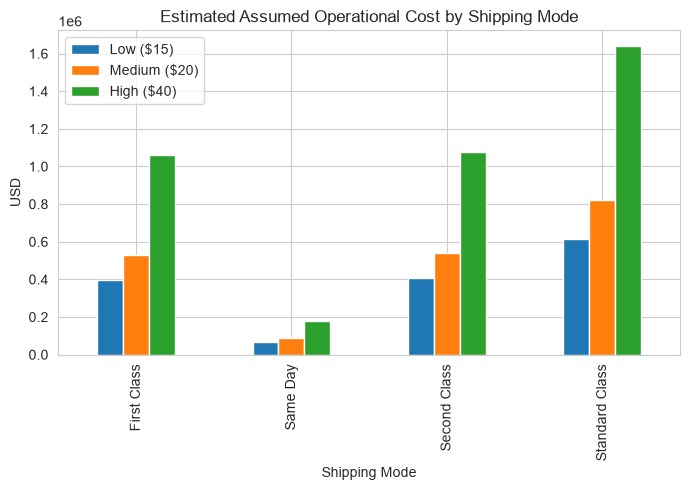

In [84]:
n_late = int((df_clean['Late_delivery_risk']==1).sum())
print(f"Total late orders: {n_late:,}")

late = df_clean[df_clean['Late_delivery_risk']==1]
total_revenue_at_risk = late['Sales'].sum()
print(f"Total revenue at risk: ${total_revenue_at_risk:,.0f}")
print()

for label, rate in [('Low ($15/order)', 15), ('Medium ($20/order)', 20), ('High ($40/order)', 40)]:
    print(f"{label}: ${rate*n_late:,.0f} total assumed operational cost")

exposure_by_mode = late.groupby('Shipping Mode').agg(
    late_orders=('Sales', 'count'),
    revenue_at_risk=('Sales', 'sum'))
exposure_by_mode['op_cost_low_15'] = exposure_by_mode['late_orders']*15
exposure_by_mode['op_cost_med_20'] = exposure_by_mode['late_orders']*20
exposure_by_mode['op_cost_high_40'] = exposure_by_mode['late_orders']*40
print()
print(exposure_by_mode.round(0))

fig, ax = plt.subplots(figsize=(7,5))
exposure_by_mode[['op_cost_low_15','op_cost_med_20','op_cost_high_40']].plot(kind='bar', ax=ax)
ax.set_title('Estimated Assumed Operational Cost by Shipping Mode')
ax.set_ylabel('USD')
ax.legend(['Low ($15)', 'Medium ($20)', 'High ($40)'])
plt.tight_layout()
plt.show()


**What this shows:** across 98,972 late orders, total revenue at risk is about
**\$20.1M**, and assumed operational cost ranges from **\$1.48M (low) to \$3.96M (high)**,
with a medium estimate around **\$2.0M**. Broken down by shipping mode, **Standard Class
carries the largest share of both** (about \$8.36M revenue at risk; about \$820K assumed
cost at the medium estimate) — not because it's the riskiest tier (it has the *lowest* late
rate at 38%), but because its sheer order volume outweighs its lower per-order risk. This is
a genuinely useful operational point: the biggest dollar risk isn't the "riskiest" tier by
rate, it's the highest-volume one.

*Note: the counts and dollar costs in this section are per order item (98,972 rows), not per order. They are superseded by the per-unique-order figures in Section 14a.*

## Summary & Next Steps

**Core finding:** Shipping Mode (and its paired scheduled-days field) is the dominant,
stable, statistically meaningful driver of late delivery in this dataset. Payment Type is a
real but much smaller second factor. Geography and cross-border shipping were tested and showed no effect; weather could not be tested with this data. Internal financial fields show no direct cost signal tied to lateness, so financial
exposure is calculated two ways: a hard revenue-at-risk figure from the data itself, and an
assumed operational cost from published industry benchmarks.

**Method choices, justified rather than assumed:** a chi-square/Cramer's V test confirmed
Shipping Mode's effect is real and not a statistical artifact of a large sample; a head-to-head
comparison showed Logistic Regression matches Random Forest's accuracy almost exactly, so the
interpretable model was kept rather than trading explainability away for no real gain.

**Done so far:**
- Data cleaning, quality audit, and EDA across seven categories (including Payment Type and
  Category Name)
- Chi-square + Cramer's V effect size testing, with a stated method justification
- Temporal stability check (2015–2018, with the 2018 partial-year caveat noted)
- Outside-factor testing: geography, domestic vs. international, weather feasibility
- Two classification models compared head-to-head (Random Forest, Logistic Regression), with
  a stated method justification
- Financial exposure calculated two ways: revenue at risk (hard number) and assumed
  operational cost (industry benchmark)

**Final status (Week 8):**
- Section 13 adds what the final presentation relies on: the one-line rule baseline, precision and recall,
  and the tuning check. Chart cleanup (Week 5) is done; the charts are rebuilt by `scripts/charts.py`.
- **Section 14** corrects order items vs. orders (36,043 late orders of 65,741), tests the $0.78 profit gap (not significant), and shows rates without canceled/fraud rows.
- **Section 15** repeats the split and cross-validation grouped by order and gets the same result within a point.
- **Never built:** the per-order financial loss regression, SHAP, a fraud flag, and a 14-day forecast from the
  Week 1 proposal. The data cannot support a 14-day forecast, and the dollar figures here are exposure, not loss.
- **No model was saved or deployed.** The models are checks that show Shipping Mode carries the signal;
  a one-line rule predicts as well as either model.


## 13. Final-presentation checks: baseline rule, precision/recall, tuning

These cells back slides 5 and 14 of the final deck. Everything here reuses the cleaned data and the 80/20
stratified split (`random_state=42`) from Section 10b.

**Assumption to keep in mind:** "late" is deduced (actual days > scheduled days); the dataset documents no rule.
Cell 13a-0 below shows it matches `Delivery Status` except for canceled and suspected-fraud orders, which are always 0. "Canceled and fraud orders never shipped" is itself an assumption.


In [85]:
# 13a-0. Check the "late" rule against Delivery Status and Order Status (nothing is assumed here)
print(pd.crosstab(df_clean['Delivery Status'], df_clean['Late_delivery_risk']))
print()
cf = df_clean['Order Status'].isin(['CANCELED', 'SUSPECTED_FRAUD'])
print(pd.crosstab(cf.rename('canceled or suspected fraud'), df_clean['Late_delivery_risk']))
print("\nTook longer than scheduled but flagged not-late:",
      int(((df_clean['Days for shipping (real)'] > df_clean['Days for shipment (scheduled)']) & (df_clean['Late_delivery_risk'] == 0)).sum()))

Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41589      0
Late delivery           0  98972
Shipping canceled    7754      0
Shipping on time    32193      0

Late_delivery_risk               0      1
canceled or suspected fraud              
False                        73782  98972
True                          7754      0

Took longer than scheduled but flagged not-late: 4423


In [86]:
# 13a. Baselines on the held-out test set: always-late, one-line rule, and the two models
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

yt = ylr_test
always = np.ones(len(yt), dtype=int)
rule = Xlr_test['Shipping Mode'].isin(['First Class', 'Second Class']).astype(int)
lr_pred = logreg.predict(Xlr_test)
rf_pred = rf2.predict(Xrf2_test)

rows = []
for name, pred in [('Always predict late', always), ('One-line rule (First/Second = late)', rule),
                   ('Logistic regression', lr_pred), ('Random forest', rf_pred)]:
    tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()
    rows.append({'model': name, 'accuracy': (pred == yt).mean(), 'precision': precision_score(yt, pred),
                 'recall': recall_score(yt, pred), 'F1': f1_score(yt, pred), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
pd.DataFrame(rows).round(3)

,model,accuracy,precision,recall,F1,TN,FP,FN,TP
0,Always predict late,0.548,0.548,1.000,0.708,0,16307,0,19795
1,One-line rule (First/Second = late),0.695,0.848,0.540,0.660,14394,1913,9099,10696
2,Logistic regression,0.694,0.842,0.544,0.661,14292,2015,9021,10774
3,Random forest,0.692,0.806,0.578,0.673,13549,2758,8347,11448


In [87]:
# 13b. The same rule on ALL cleaned orders, in plain counts of order items (the numbers quoted on the slides)
rule_all = df_clean['Shipping Mode'].isin(['First Class', 'Second Class']).astype(int)
tn, fp, fn, tp = confusion_matrix(df_clean['Late_delivery_risk'], rule_all).ravel()
print(f"Rows: {len(df_clean):,}   Late: {int(df_clean['Late_delivery_risk'].sum()):,} ({df_clean['Late_delivery_risk'].mean():.1%})")
print(f"Rule accuracy: {(rule_all == df_clean['Late_delivery_risk']).mean():.1%}")
print(f"Rule precision (flagged and really late): {tp/(tp+fp):.1%}")
print(f"Rule recall (late orders it catches):     {tp/(tp+fn):.1%}")
print(f"Missed late orders: {fn:,}   False alarms: {fp:,}")

Rows: 180,508   Late: 98,972 (54.8%)
Rule accuracy: 69.5%
Rule precision (flagged and really late): 84.9%
Rule recall (late orders it catches):     54.1%
Missed late orders: 45,475   False alarms: 9,529


In [88]:
# 13c. Tuning check: 3-fold CV AUC on the training split only (the test set is not touched here)
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("Logistic regression, regularization strength C:")
for C in [0.01, 0.1, 1, 10]:
    p = Pipeline([('pre', pre), ('clf', LogisticRegression(C=C, max_iter=1000))])
    print(f"  C={C:<5} CV AUC = {cross_val_score(p, Xlr_train, ylr_train, cv=cv, scoring='roc_auc').mean():.4f}")

print("Random forest, max_depth (100 trees):")
for d in [5, 10, 15]:
    m = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1)
    print(f"  depth={d:<3} CV AUC = {cross_val_score(m, Xrf2_train, yrf2_train, cv=cv, scoring='roc_auc').mean():.4f}")

Logistic regression, regularization strength C:
  C=0.01  CV AUC = 0.7411
  C=0.1   CV AUC = 0.7412
  C=1     CV AUC = 0.7412
  C=10    CV AUC = 0.7412
Random forest, max_depth (100 trees):
  depth=5   CV AUC = 0.7400
  depth=10  CV AUC = 0.7422
  depth=15  CV AUC = 0.7402


In [89]:
# 13d. Decision cutoff for the logistic regression. NOTE: this scores the cutoffs on the test set for reporting only;
# the cutoff used everywhere else stays at 0.5, so the test set was not used to choose it.
proba = logreg.predict_proba(Xlr_test)[:, 1]
for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
    print(f"cutoff {th}: accuracy {((proba > th).astype(int) == ylr_test).mean():.4f}")

cutoff 0.3: accuracy 0.5637
cutoff 0.4: accuracy 0.6195
cutoff 0.5: accuracy 0.6943
cutoff 0.6: accuracy 0.6950
cutoff 0.7: accuracy 0.6886


**Reading these results honestly**
- The one-line rule matches both models on accuracy, so Shipping Mode (the class) carries nearly all the signal.
- Precision is high (when the rule says late, it usually is) but recall is low: it misses late Standard Class orders.
- Tuning changed nothing material, so the untuned defaults are acceptable. Only a few settings were tried.
- Correlation is not cause. A test would apply a fix to one First Class group and compare late rates.
- Canceled and suspected-fraud orders are never flagged late by construction, so this data cannot show whether
  lateness causes cancellation.
- "Always predict late" has the best F1 (0.708) because its recall is 1.0. F1 does not penalize it for being wrong on
  every on-time order, which is why accuracy and recall are reported next to it.
- Year-to-year stability (Section 7) was judged by eye, not tested. Same Day moves between 41.7% and 50.2% across years.
- The domestic vs. international test (Section 8) uses `Order Country == 'Estados Unidos'`. The location fields look
  synthetic and the shipping origin is unknown, so this test is weaker than it looks.


## 14. Corrections after review (order items vs. orders, and two untested claims)

Checking this notebook against its own outputs turned up three things to fix or test.

1. **Rows are order items, not orders.** Earlier sections call each row an "order". The data has
   one row per order item, and every item in an order carries the same late flag. Counts quoted as "orders" are
   item counts, and the handling cost ($15 to $40 each) should be multiplied by unique late orders, not rows.
   Late rates are essentially unaffected, because every item of an order shares its flag (for example Same Day is 46.1% by order and 45.7% by item).
2. **The $0.78 profit gap** was reported without a test. It is tested below.
3. **Canceled and suspected-fraud rows** are 0% late by construction and sit in every late-rate figure above,
   which pulls rates slightly down. The rates without them are shown below.

In [90]:
# 14a. Rows vs. unique orders, and handling cost per unique late order
n_rows = len(df_clean); n_late_rows = int(df_clean['Late_delivery_risk'].sum())
orders = df_clean.groupby('Order Id')['Late_delivery_risk'].agg(['min', 'max'])
n_orders = len(orders); n_late_orders = int(orders['max'].sum())
print(f"Rows (order items): {n_rows:,}    Unique orders: {n_orders:,}    Items per order: {n_rows/n_orders:.2f}")
print(f"Every order has one late flag for all its items: {(orders['min'] == orders['max']).all()}")
print(f"Late rows: {n_late_rows:,}    Late unique orders: {n_late_orders:,} ({n_late_orders/n_orders:.1%} of orders)")
print()
for label, rate in [('Low ($15)', 15), ('Medium ($20)', 20), ('High ($40)', 40)]:
    print(f"{label}: per late row ${rate*n_late_rows:,.0f}   per unique late order ${rate*n_late_orders:,.0f}")
print(f"\nRevenue on late items (sum of Sales) is unchanged: ${df_clean.loc[df_clean['Late_delivery_risk']==1, 'Sales'].sum():,.0f}")
print(f"Order cities: {df_clean['Order City'].nunique():,}   Order countries: {df_clean['Order Country'].nunique()}   Customer countries: {df_clean['Customer Country'].nunique()}")

Rows (order items): 180,508    Unique orders: 65,741    Items per order: 2.75
Every order has one late flag for all its items: True
Late rows: 98,972    Late unique orders: 36,043 (54.8% of orders)

Low ($15): per late row $1,484,580   per unique late order $540,645
Medium ($20): per late row $1,979,440   per unique late order $720,860
High ($40): per late row $3,958,880   per unique late order $1,441,720

Revenue on late items (sum of Sales) is unchanged: $20,124,855
Order cities: 3,597   Order countries: 164   Customer countries: 2


In [91]:
# 14a-2. Late unique orders and handling cost by Shipping Mode (per unique order)
ord_mode = df_clean.groupby('Order Id').agg(mode=('Shipping Mode', 'first'), late=('Late_delivery_risk', 'max'))
by_mode = ord_mode.groupby('mode').agg(orders=('late', 'size'), late_orders=('late', 'sum'))
by_mode['late_rate_%'] = (by_mode['late_orders'] / by_mode['orders'] * 100).round(2)
for r in (15, 20, 40):
    by_mode[f'cost_${r}'] = by_mode['late_orders'] * r
by_mode.loc['Total'] = by_mode.sum(numeric_only=True)
by_mode.loc['Total', 'late_rate_%'] = round(by_mode.loc['Total', 'late_orders'] / by_mode.loc['Total', 'orders'] * 100, 2)
by_mode = by_mode.astype({'orders': int, 'late_orders': int, 'cost_$15': int, 'cost_$20': int, 'cost_$40': int})
by_mode

,orders,late_orders,late_rate_%,cost_$15,cost_$20,cost_$40
mode,,,,,,
First Class,10077,9600,95.27,144000,192000,384000
Same Day,3571,1648,46.15,24720,32960,65920
Second Class,12776,9802,76.72,147030,196040,392080
Standard Class,39317,14993,38.13,224895,299860,599720
Total,65741,36043,54.83,540645,720860,1441720


In [92]:
# 14b. Is the $0.78 profit gap distinguishable from noise?
from scipy.stats import ttest_ind, mannwhitneyu
a = df_clean.loc[df_clean['Late_delivery_risk'] == 1, 'Benefit per order']
b = df_clean.loc[df_clean['Late_delivery_risk'] == 0, 'Benefit per order']
print(f"Mean benefit per item: late ${a.mean():.2f}, on time ${b.mean():.2f}, gap ${a.mean()-b.mean():.2f}")
print(f"Welch t-test p = {ttest_ind(a, b, equal_var=False).pvalue:.3f}    Mann-Whitney p = {mannwhitneyu(a, b).pvalue:.3f}")

Mean benefit per item: late $21.62, on time $22.40, gap $-0.78
Welch t-test p = 0.112    Mann-Whitney p = 0.209


In [93]:
# 14c. Late rates with and without canceled / suspected-fraud rows
cf = df_clean['Order Status'].isin(['CANCELED', 'SUSPECTED_FRAUD'])
print(f"Overall late rate: all rows {df_clean['Late_delivery_risk'].mean():.1%}   excluding canceled/fraud {df_clean.loc[~cf, 'Late_delivery_risk'].mean():.1%}")
print(pd.DataFrame({'all rows': df_clean.groupby('Shipping Mode')['Late_delivery_risk'].mean(),
                    'excluding canceled/fraud': df_clean[~cf].groupby('Shipping Mode')['Late_delivery_risk'].mean()}).mul(100).round(1))

Overall late rate: all rows 54.8%   excluding canceled/fraud 57.3%
                all rows  excluding canceled/fraud
Shipping Mode                                     
First Class         95.3                     100.0
Same Day            45.7                      47.9
Second Class        76.6                      79.8
Standard Class      38.1                      39.8


In [94]:
# 14d. Loss scenarios (slide 13): if 1%, 5% or 10% of the sales on late items were lost. Illustrative, not findings.
late_sales = df_clean.loc[df_clean['Late_delivery_risk'] == 1, 'Sales'].sum()
print("Illustrative, not findings:", {f"{p}%": f"${late_sales * p / 100 / 1e6:.2f}M" for p in (1, 5, 10)})

Illustrative, not findings: {'1%': '$0.20M', '5%': '$1.01M', '10%': '$2.01M'}


In [95]:
# 14e. Evidence for the lateness rule (slide 12): how actual vs scheduled days line up with Delivery Status
diff = df_clean['Days for shipping (real)'] - df_clean['Days for shipment (scheduled)']
print("Late items: days over schedule ranges from", diff[df_clean['Late_delivery_risk'] == 1].min(), "to", diff[df_clean['Late_delivery_risk'] == 1].max())
print("'Shipping on time': days over schedule =", sorted(diff[df_clean['Delivery Status'] == 'Shipping on time'].astype(int).unique().tolist()))
print("'Advance shipping': days over schedule =", sorted(diff[df_clean['Delivery Status'] == 'Advance shipping'].astype(int).unique().tolist()))
over_not_late = (diff > 0) & (df_clean['Late_delivery_risk'] == 0)
print("Over schedule but not flagged late:", int(over_not_late.sum()), "| of these canceled or suspected fraud:", int(df_clean.loc[over_not_late, 'Order Status'].isin(['CANCELED', 'SUSPECTED_FRAUD']).sum()))
print("First Class: distinct actual shipping days =", sorted(df_clean.loc[df_clean['Shipping Mode'] == 'First Class', 'Days for shipping (real)'].astype(int).unique().tolist()))

Late items: days over schedule ranges from 1 to 4
'Shipping on time': days over schedule = [0]
'Advance shipping': days over schedule = [-2, -1]
Over schedule but not flagged late: 4423 | of these canceled or suspected fraud: 4423
First Class: distinct actual shipping days = [2]


**What changes.** Handling cost should be computed per unique late order ($0.54M to $1.44M, 14a), not per late row ($1.5M to $4.0M), which is about 2.7 times too high. The $20.1M revenue figure is unchanged, the late rates are essentially unaffected (Same Day is 46.1% by order, 45.7% by item), and the rule and the models are unaffected. The profit gap
is not statistically distinguishable from zero (14b), so it should not be quoted as a finding. Excluding canceled and fraud rows lifts every rate
a little and puts First Class at 100% (14c), which strengthens the First Class finding.

## 15. Robustness: split by order instead of by row

Each row is an order item and an order has about 2.75 items, so the random row split used above can put items of the same order in both train and test. That could make scores optimistic. Here the split and the cross-validation keep each order's items together (`GroupShuffleSplit`, `GroupKFold` on `Order Id`).

In [96]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

d_ = df_clean.reset_index(drop=True)
Xg, yg, gg = d_[features_lr], d_['Late_delivery_risk'], d_['Order Id']
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(Xg, yg, gg))
print("Orders shared between train and test:", len(set(gg.iloc[tr]) & set(gg.iloc[te])))

lr_g = Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=1000))]).fit(Xg.iloc[tr], yg.iloc[tr])
p_lr = lr_g.predict_proba(Xg.iloc[te])[:, 1]

Xg_enc = Xg.copy()
for c in cat_cols_lr:
    Xg_enc[c] = LabelEncoder().fit_transform(Xg_enc[c].astype(str))
rf_g = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1).fit(Xg_enc.iloc[tr], yg.iloc[tr])
p_rf = rf_g.predict_proba(Xg_enc.iloc[te])[:, 1]
rule_g = Xg.iloc[te]['Shipping Mode'].isin(['First Class', 'Second Class']).astype(int)

print(f"One-line rule:       accuracy {(rule_g == yg.iloc[te]).mean():.4f}")
print(f"Logistic regression: accuracy {accuracy_score(yg.iloc[te], p_lr > .5):.4f}  AUC {roc_auc_score(yg.iloc[te], p_lr):.4f}")
print(f"Random forest:       accuracy {accuracy_score(yg.iloc[te], p_rf > .5):.4f}  AUC {roc_auc_score(yg.iloc[te], p_rf):.4f}")

gk = GroupKFold(n_splits=3)
print("\nGrouped 3-fold CV AUC on the training part:")
for dpt in [5, 10, 15]:
    m = RandomForestClassifier(n_estimators=100, max_depth=dpt, random_state=42, n_jobs=-1)
    print(f"  RF depth={dpt:<3}", round(cross_val_score(m, Xg_enc.iloc[tr], yg.iloc[tr], cv=gk, groups=gg.iloc[tr], scoring='roc_auc').mean(), 4))
for Cc in [0.01, 1, 10]:
    m = Pipeline([('pre', pre), ('clf', LogisticRegression(C=Cc, max_iter=1000))])
    print(f"  LR C={Cc:<5}", round(cross_val_score(m, Xg.iloc[tr], yg.iloc[tr], cv=gk, groups=gg.iloc[tr], scoring='roc_auc').mean(), 4))

Orders shared between train and test: 0
One-line rule:       accuracy 0.6996
Logistic regression: accuracy 0.6985  AUC 0.7408
Random forest:       accuracy 0.6952  AUC 0.7387

Grouped 3-fold CV AUC on the training part:
  RF depth=5   0.7383
  RF depth=10  0.7381
  RF depth=15  0.7323
  LR C=0.01  0.7374
  LR C=1     0.7373
  LR C=10    0.7374


**Result.** Splitting by order changes the scores by well under one point (the rule 70.0%, logistic regression 69.9%, random forest 69.5%; AUC about 0.74), so the row split did not inflate them. The conclusion is unchanged: the one-line rule matches both models on accuracy, and tuning moves nothing.

**What each part of the test data was used for.** Settings were chosen on cross-validation within the training part only (depth 10 and 100 trees were my starting choices; see Section 9). The held-out test part was then used to report accuracy and AUC (Sections 9, 10b, 13a, 15). The cutoff sweep in 13d is scored on the test part for reporting only; the cutoff stayed at 0.5.

## 16. Sensitivity checks

Section 13 and 15 used choices I made without testing alternatives (seed, split size, folds, trees, encoding, cutoff). This section tries the alternatives, on the order-grouped split from Section 15, and reports them side by side. Nothing above this section was changed.

In [97]:
from sklearn.preprocessing import OneHotEncoder as _OHE
from sklearn.metrics import precision_score, recall_score

def _split(seed, test_size):
    return next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed).split(Xg, yg, gg))

def _lr():
    return Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=1000))])

def _rule(idx):
    return Xg.iloc[idx]['Shipping Mode'].isin(['First Class', 'Second Class']).astype(int)

# 16a. Seeds 0-4 for the grouped split: logistic regression and the one-line rule
rows = []
for s in range(5):
    a, b = _split(s, 0.2)
    p = _lr().fit(Xg.iloc[a], yg.iloc[a]).predict_proba(Xg.iloc[b])[:, 1]
    rows.append({'seed': s, 'rule acc': (_rule(b) == yg.iloc[b]).mean(), 'LR acc': ((p > .5) == yg.iloc[b]).mean(), 'LR AUC': roc_auc_score(yg.iloc[b], p)})
t16a = pd.DataFrame(rows).set_index('seed')
print("16a. Five different split seeds (80/20, grouped by order)")
print(t16a.round(4)); print("range (max - min):", (t16a.max() - t16a.min()).round(4).to_dict())

# 16b. 70/30 vs 80/20 (seed 42)
rows = []
for ts in (0.2, 0.3):
    a, b = _split(42, ts)
    p = _lr().fit(Xg.iloc[a], yg.iloc[a]).predict_proba(Xg.iloc[b])[:, 1]
    rows.append({'test share': ts, 'rule acc': (_rule(b) == yg.iloc[b]).mean(), 'LR acc': ((p > .5) == yg.iloc[b]).mean(), 'LR AUC': roc_auc_score(yg.iloc[b], p)})
print("\n16b. 80/20 vs 70/30 split (seed 42)"); print(pd.DataFrame(rows).set_index('test share').round(4))

# 16c. 5-fold vs 3-fold grouped CV, random forest depth 5/10/15 (training part of the Section 15 split)
a, b = _split(42, 0.2)
rows = []
for dpt in (5, 10, 15):
    r = {'depth': dpt}
    for k in (3, 5):
        m = RandomForestClassifier(n_estimators=100, max_depth=dpt, random_state=42, n_jobs=-1)
        r[f'{k}-fold AUC'] = cross_val_score(m, Xg_enc.iloc[a], yg.iloc[a], cv=GroupKFold(n_splits=k), groups=gg.iloc[a], scoring='roc_auc').mean()
    rows.append(r)
print("\n16c. Random forest CV AUC, 3 folds vs 5 folds"); print(pd.DataFrame(rows).set_index('depth').round(4))

# 16d. 200 trees vs 100 trees, and 16e. one-hot vs label encoding (random forest, depth 10, test part)
Xg_oh = pd.get_dummies(Xg, columns=cat_cols_lr, dtype=float)
rows = []
for name, Xuse, n_est in [('100 trees, label codes (as used)', Xg_enc, 100), ('200 trees, label codes', Xg_enc, 200), ('100 trees, one-hot', Xg_oh, 100)]:
    m = RandomForestClassifier(n_estimators=n_est, max_depth=10, random_state=42, n_jobs=-1).fit(Xuse.iloc[a], yg.iloc[a])
    p = m.predict_proba(Xuse.iloc[b])[:, 1]
    rows.append({'random forest, depth 10': name, 'acc': ((p > .5) == yg.iloc[b]).mean(), 'AUC': roc_auc_score(yg.iloc[b], p)})
print("\n16d/16e. Trees and encoding"); print(pd.DataFrame(rows).set_index('random forest, depth 10').round(4))

# 16f. Cutoff: precision and recall (logistic regression, test part of the Section 15 split)
p = _lr().fit(Xg.iloc[a], yg.iloc[a]).predict_proba(Xg.iloc[b])[:, 1]
rows = [{'cutoff': c, 'accuracy': ((p > c) == yg.iloc[b]).mean(), 'precision': precision_score(yg.iloc[b], p > c), 'recall': recall_score(yg.iloc[b], p > c)} for c in (0.3, 0.4, 0.5, 0.6, 0.7)]
print("\n16f. Cutoff (logistic regression)"); print(pd.DataFrame(rows).set_index('cutoff').round(4))

16a. Five different split seeds (80/20, grouped by order)
      rule acc  LR acc  LR AUC
seed                          
0       0.6990  0.6998  0.7401
1       0.6995  0.6994  0.7418
2       0.6976  0.6967  0.7372
3       0.6942  0.6934  0.7363
4       0.7000  0.7002  0.7432
range (max - min): {'rule acc': 0.0057, 'LR acc': 0.0068, 'LR AUC': 0.007}

16b. 80/20 vs 70/30 split (seed 42)
            rule acc  LR acc  LR AUC
test share                          
0.2           0.6996  0.6985  0.7408
0.3           0.6976  0.6967  0.7380

16c. Random forest CV AUC, 3 folds vs 5 folds
       3-fold AUC  5-fold AUC
depth                        
5          0.7383      0.7380
10         0.7381      0.7384
15         0.7323      0.7333

16d/16e. Trees and encoding
                                     acc     AUC
random forest, depth 10                         
100 trees, label codes (as used)  0.6952  0.7387
200 trees, label codes            0.6950  0.7384
100 trees, one-hot                0.6974  0

**What happened, in plain words.**
- **Seeds (16a).** Across five different splits, accuracy ran from 69.3% to 70.0% (a spread of about 0.6 to 0.7 points) and AUC from 0.736 to 0.743. In every seed the one-line rule and logistic regression were within 0.1 point of each other. The gaps I quote between the rule, logistic regression and random forest (up to about 0.4 points) are smaller than this split-to-split variation, so the order of the three should not be read as meaningful. What holds is that they are about equal. Random forest was run on one seed only.
- **Split size (16b).** 70/30 instead of 80/20 moved scores by 0.2 points or less (rule 70.0% to 69.8%, logistic regression 69.9% to 69.7%, AUC 0.7408 to 0.7380).
- **Folds (16c).** 5-fold CV gave the same pattern as 3-fold. Depth 5 and depth 10 are about equal (0.7380 and 0.7384 at 5 folds), and depth 15 is lower in both (0.7323 and 0.7333). So the three depths score about the same on the row-split check in Section 13c (a spread of 0.002), but not on the order-grouped CV, where depth 15 is about 0.006 lower.
- **Trees (16d).** 200 trees instead of 100 changed nothing (accuracy 69.50% against 69.52%, AUC 0.7384 against 0.7387).
- **Encoding (16e).** One-hot instead of label codes helped the random forest slightly (accuracy 69.74% against 69.52%, AUC 0.7395 against 0.7387). That is inside the seed variation above, and it is still below the one-line rule on the same split (69.96%).
- **Cutoff (16f).** This is where the result does change, as a trade-off. At 0.3 the model finds 97.4% of late orders, but only 55.5% of its "late" calls are right. At 0.5 it finds 55.3% with 84.1% precision, and at 0.7 it finds 51.9% with 85.9% precision. Accuracy is highest at 0.5 to 0.6. 0.5 is the default, within about 0.1 point of the best cutoff (0.6 scores 69.96% against 69.85% at 0.5 on this split), and I did not weigh the cost of a missed late order against a false alarm.

**Net effect.** None of the alternatives overturns the conclusion: the one-line rule and the models are about equal on accuracy, and the class carries the signal. What this section adds is that differences of a few tenths of a point between them are within noise.